# Seggiolini auto: più variabili e variabili qualitative

*Metodi Matematici e Statistici per le Decisioni Economiche · A.A. 2026/27 · Lezione 2*

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vincnardelli/msd/blob/main/codice/2/regressione_carseats.ipynb)

Un produttore di seggiolini auto vende in 400 negozi e vuole capire quanto contano prezzo, pubblicità e posizione sugli scaffali. È il codice della seconda parte della lezione 2: modelli con più variabili, la statistica $F$, l'$R^2$ aggiustato e le variabili qualitative (dummy).

| colonna | cosa misura |
|---|---|
| `Sales` | vendite del negozio, in migliaia di unità |
| `Price` | il nostro prezzo, in dollari |
| `CompPrice` | il prezzo del concorrente nella stessa zona, in dollari |
| `Advertising` | budget pubblicitario locale, in migliaia di dollari |
| `Income` | reddito medio della zona, in migliaia di dollari |
| `Population` | popolazione della zona, in migliaia |
| `Age` | età media della zona |
| `Education` | anni di istruzione medi della zona |
| `ShelveLoc` | posizione sugli scaffali: `Bad`, `Medium`, `Good` |
| `Urban` | il negozio è in città: `Yes` o `No` |
| `US` | il negozio è negli Stati Uniti: `Yes` o `No` |

In [1]:
import polars as pl            # tabelle di dati
from plotnine import *         # grafici
import statsmodels.formula.api as smf   # modelli statistici (regressione)

In [2]:
car = pl.read_csv("https://www.vincnardelli.com/msd/dati/carseats.csv")  # carico i dati dal sito
car.head()

Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
f64,i64,i64,i64,i64,i64,str,i64,i64,str,str
9.5,138,73,11,276,120,"""Bad""",42,17,"""Yes""","""Yes"""
11.22,111,48,16,260,83,"""Good""",65,10,"""Yes""","""Yes"""
10.06,113,35,10,269,80,"""Medium""",59,12,"""Yes""","""Yes"""
7.4,117,100,4,466,97,"""Medium""",55,14,"""Yes""","""Yes"""
4.15,141,64,3,340,128,"""Bad""",38,13,"""Yes""","""No"""


### 1. Il prezzo da solo

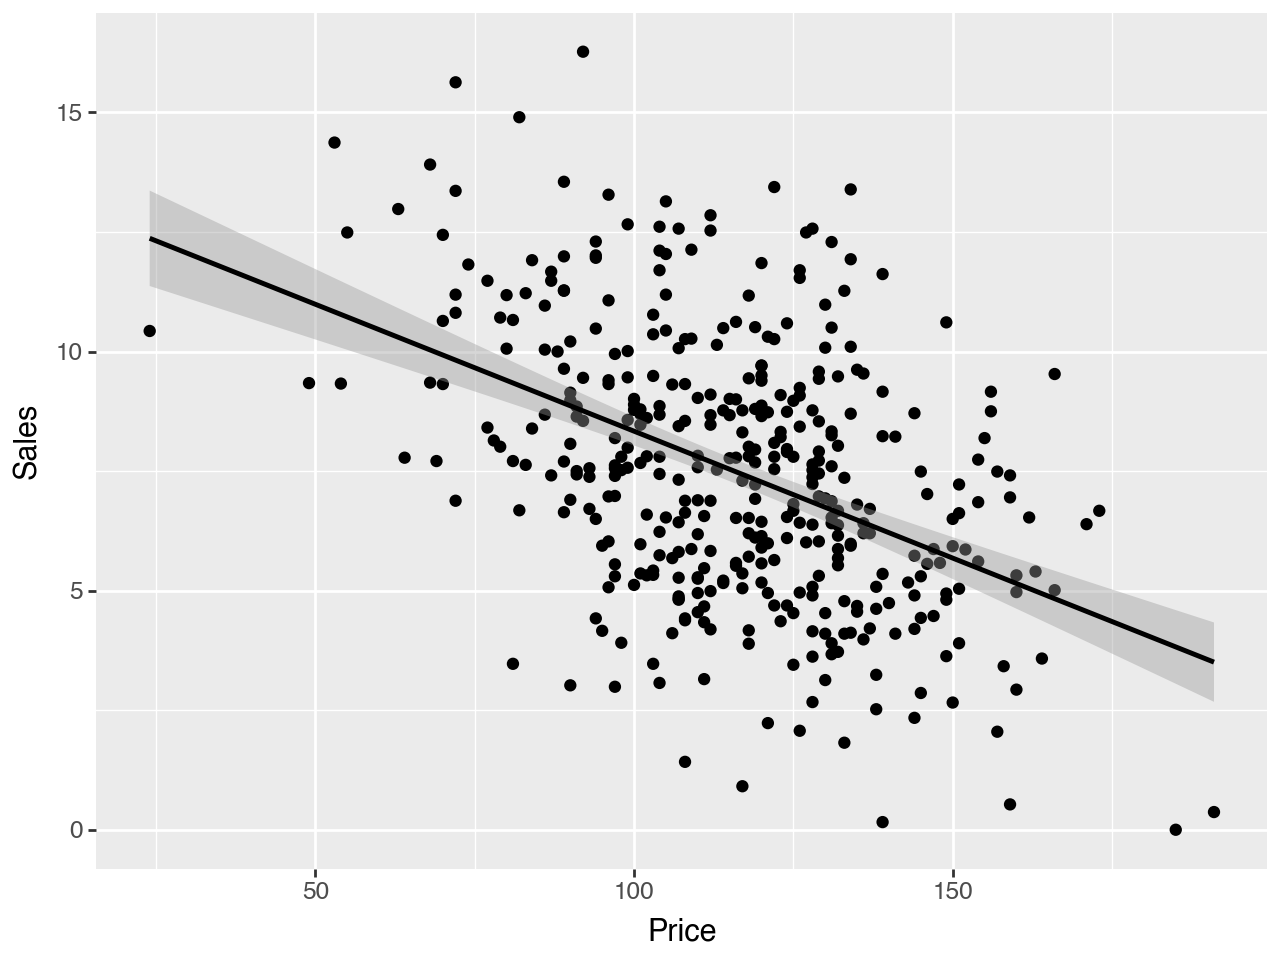

In [3]:
ggplot(car, aes(x="Price", y="Sales")) + geom_point() + geom_smooth(method="lm")

In [4]:
modello1 = smf.ols("Sales ~ Price", data=car).fit()
modello1.params

Intercept    13.641915
Price        -0.053073
dtype: float64

Ogni dollaro in più di prezzo, 53 unità vendute in meno. Ma il prezzo da solo spiega poco: $R^2$ = 0,20.

### 2. Il nostro prezzo e quello del concorrente

In [5]:
car.select("Sales", "Price", "CompPrice").corr()

Sales,Price,CompPrice
f64,f64,f64
1.0,-0.444951,0.064079
-0.444951,1.0,0.584848
0.064079,0.584848,1.0


In [6]:
modello2 = smf.ols("Sales ~ Price + CompPrice", data=car).fit()
modello2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.358
Model:                            OLS   Adj. R-squared:                  0.355
Method:                 Least Squares   F-statistic:                     110.6
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           6.58e-39
Time:                        12:16:38   Log-Likelihood:                -893.77
No. Observations:                 400   AIC:                             1794.
Df Residuals:                     397   BIC:                             1806.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.2787      0.933      6.731      0.000       4.445       8.112
Price         -0.0875      0.006    -14.788      0.000      -0.099      -0.076
CompPrice      0.0908      0.009      9.941      0.000       0.073       0.109
==============================================================================
Omnibus:                        8.676   Durbin-Watson:                   1.943
Prob(Omnibus):                  0.013   Jarque-Bera (JB):                8.436
Skew:                           0.317   Prob(JB):                       0.0147
Kurtosis:                       2.675   Cond. No.                     1.42e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.42e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Da solo, il prezzo del concorrente sembra non contare: la correlazione con le vendite è 0,06. Ma i due prezzi si muovono insieme (correlazione 0,58): dove il concorrente è caro lo siamo anche noi. **A parità del nostro prezzo**, ogni dollaro in più del concorrente porta 91 unità in più, ed è significativo. E il nostro prezzo pesa più di prima: 87 unità in meno per dollaro.

### 3. Altre variabili: la statistica $F$

In alto a destra nel summary: `F-statistic` e il suo p-value, `Prob (F-statistic)`. L'ipotesi è che **nessuna** variabile conti: se il p-value è sotto 0,05, almeno una serve.

In [7]:
modello3 = smf.ols("Sales ~ Price + CompPrice + Advertising + Income + Age", data=car).fit()
modello3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.540
Model:                            OLS   Adj. R-squared:                  0.534
Method:                 Least Squares   F-statistic:                     92.62
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           2.70e-64
Time:                        12:16:38   Log-Likelihood:                -826.92
No. Observations:                 400   AIC:                             1666.
Df Residuals:                     394   BIC:                             1690.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       7.1092      0.944      7.531      0.000       5.253       8.965
Price          -0.0925      0.005    -18.347      0.000      -0.102      -0.083
CompPrice       0.0939      0.008     12.051      0.000       0.079       0.109
Advertising     0.1306      0.015      8.963      0.000       0.102       0.159
Income          0.0131      0.003      3.779      0.000       0.006       0.020
Age            -0.0450      0.006     -7.503      0.000      -0.057      -0.033
==============================================================================
Omnibus:                        9.073   Durbin-Watson:                   1.963
Prob(Omnibus):                  0.011   Jarque-Bera (JB):                8.154
Skew:                           0.288   Prob(JB):                       0.0170
Kurtosis:                       2.602   Cond. No.                     1.89e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.89e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [8]:
modello3.fvalue, modello3.f_pvalue

(92.6155334038887, 2.70215320388301e-64)

$F$ = 92,6, con p-value praticamente zero: il modello serve. Tutte e cinque le variabili sono significative e l'$R^2$ sale a 0,54. Ogni mille dollari di pubblicità, 131 unità in più, a parità del resto.

### 4. L'$R^2$ aggiustato: aggiungere variabili ha un prezzo

In [9]:
modello4 = smf.ols("Sales ~ Price + CompPrice + Advertising + Income + Age + Population + Education", data=car).fit()
modello4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.542
Model:                            OLS   Adj. R-squared:                  0.533
Method:                 Least Squares   F-statistic:                     66.18
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.41e-62
Time:                        12:16:38   Log-Likelihood:                -826.32
No. Observations:                 400   AIC:                             1669.
Df Residuals:                     392   BIC:                             1701.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       7.7077      1.118      6.896      0.000       5.510       9.905
Price          -0.0925      0.005    -18.314      0.000      -0.102      -0.083
CompPrice       0.0939      0.008     11.980      0.000       0.079       0.109
Advertising     0.1309      0.015      8.654      0.000       0.101       0.161
Income          0.0129      0.003      3.703      0.000       0.006       0.020
Age            -0.0450      0.006     -7.485      0.000      -0.057      -0.033
Population     -0.0001      0.001     -0.180      0.857      -0.001       0.001
Education      -0.0400      0.037     -1.077      0.282      -0.113       0.033
==============================================================================
Omnibus:                        8.263   Durbin-Watson:                   1.969
Prob(Omnibus):                  0.016   Jarque-Bera (JB):                7.705
Skew:                           0.288   Prob(JB):                       0.0212
Kurtosis:                       2.639   Cond. No.                     4.05e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.05e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [10]:
modello3.rsquared, modello4.rsquared

(0.5402983706597249, 0.5416606311947556)

In [11]:
modello3.rsquared_adj, modello4.rsquared_adj

(0.5344645936376401, 0.5334759996089478)

`Population` e `Education` non sono significative (p-value 0,86 e 0,28). L'$R^2$ sale lo stesso, da 0,5403 a 0,5417: non scende mai quando si aggiunge una variabile. L'$R^2$ aggiustato invece scende, da 0,5345 a 0,5335: meglio il modello senza.

### 5. Una dummy da sola: i negozi negli Stati Uniti

`US` è testo (`Yes`/`No`): nel modello entra come una colonna 0/1, che vale 1 per i negozi negli Stati Uniti.

In [12]:
car = car.with_columns(us=(pl.col("US") == "Yes").cast(pl.Int8))
car.select("US", "us").head()

US,us
str,i8
"""Yes""",1
"""Yes""",1
"""Yes""",1
"""Yes""",1
"""No""",0


In [13]:
modello5 = smf.ols("Sales ~ us", data=car).fit()
modello5.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                  0.029
Method:                 Least Squares   F-statistic:                     12.89
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           0.000372
Time:                        12:16:38   Log-Likelihood:                -975.98
No. Observations:                 400   AIC:                             1956.
Df Residuals:                     398   BIC:                             1964.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.8230      0.234     29.215      0.000       6.364       7.282
us             1.0439      0.291      3.590      0.000       0.472       1.616
==============================================================================
Omnibus:                        1.471   Durbin-Watson:                   1.902
Prob(Omnibus):                  0.479   Jarque-Bera (JB):                1.443
Skew:                           0.146   Prob(JB):                        0.486
Kurtosis:                       2.973   Cond. No.                         3.12
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [14]:
car.group_by("US").agg(pl.col("Sales").mean())

US,Sales
str,f64
"""Yes""",7.866899
"""No""",6.823028


L'intercetta, 6,82, è la media delle vendite fuori dagli Stati Uniti (`us` = 0). Il coefficiente, 1,04, è la **differenza** tra le due medie: i negozi negli Stati Uniti vendono 1.044 unità in più, ed è significativo (p-value 0,0004). Lo si vede anche dalle medie dei due gruppi.

### 6. Una dummy più un'altra variabile

In [15]:
modello6 = smf.ols("Sales ~ Price + us", data=car).fit()
modello6.params

Intercept    13.030793
Price        -0.054478
us            1.199643
dtype: float64

Due rette **parallele**, con la stessa pendenza per il prezzo (−0,0545): quella dei negozi negli Stati Uniti è più alta di 1,20, cioè 1.200 unità in più a parità di prezzo.

In [16]:
modello7 = smf.ols("Sales ~ Advertising + us", data=car).fit()
modello7.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.073
Model:                            OLS   Adj. R-squared:                  0.068
Method:                 Least Squares   F-statistic:                     15.57
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           3.09e-07
Time:                        12:16:38   Log-Likelihood:                -967.25
No. Observations:                 400   AIC:                             1940.
Df Residuals:                     397   BIC:                             1952.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       6.7630      0.229     29.503      0.000       6.312       7.214
Advertising     0.1185      0.028      4.209      0.000       0.063       0.174
us             -0.0818      0.391     -0.209      0.834      -0.850       0.686
==============================================================================
Omnibus:                        3.504   Durbin-Watson:                   1.953
Prob(Omnibus):                  0.173   Jarque-Bera (JB):                3.243
Skew:                           0.203   Prob(JB):                        0.198
Kurtosis:                       3.172   Cond. No.                         28.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [17]:
car.group_by("US").agg(pl.col("Advertising").mean())

US,Advertising
str,f64
"""Yes""",10.007752
"""No""",0.507042


Con la pubblicità nel modello, la differenza degli Stati Uniti sparisce: coefficiente −0,08, p-value 0,83. Fuori dagli Stati Uniti i negozi quasi non fanno pubblicità: i negozi americani non vendono di più perché sono americani, ma perché fanno pubblicità. È lo stesso effetto dei giornali nei dati Advertising.

### 7. Più di due categorie: la posizione sugli scaffali

`ShelveLoc` ha tre categorie: servono **due** colonne 0/1, `good` e `medium`. La terza, `Bad`, è la categoria di riferimento e non ha una colonna.

In [18]:
car = car.with_columns(
    good=(pl.col("ShelveLoc") == "Good").cast(pl.Int8),
    medium=(pl.col("ShelveLoc") == "Medium").cast(pl.Int8),
)
car.select("ShelveLoc", "good", "medium").head()

ShelveLoc,good,medium
str,i8,i8
"""Bad""",0,0
"""Good""",1,0
"""Medium""",0,1
"""Medium""",0,1
"""Bad""",0,0


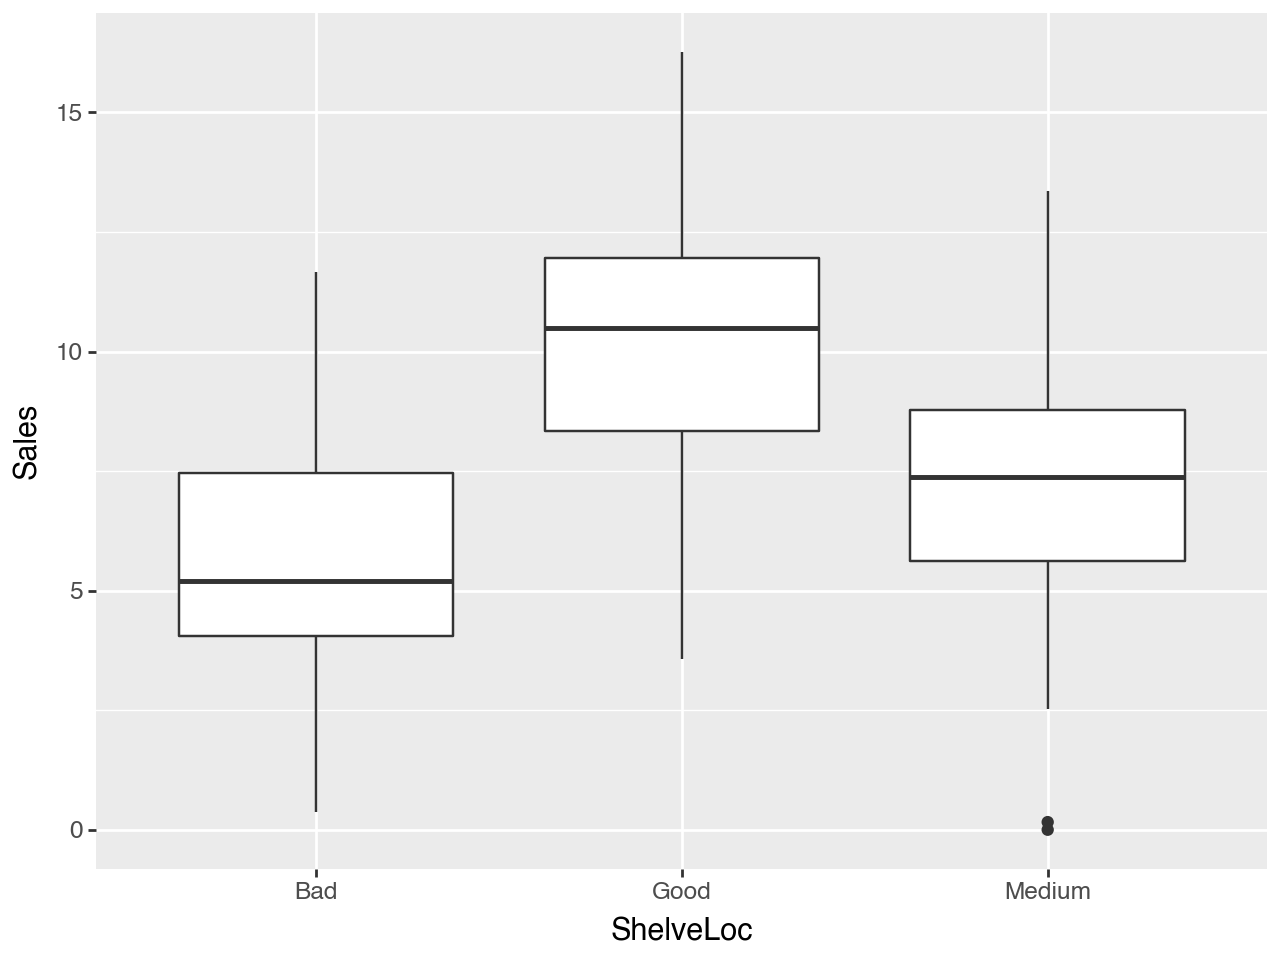

In [19]:
ggplot(car, aes(x="ShelveLoc", y="Sales")) + geom_boxplot()

In [20]:
modello8 = smf.ols("Sales ~ good + medium", data=car).fit()
modello8.params

Intercept    5.522917
good         4.691083
medium       1.783659
dtype: float64

In [21]:
car.group_by("ShelveLoc").agg(pl.col("Sales").mean())

ShelveLoc,Sales
str,f64
"""Medium""",7.306575
"""Bad""",5.522917
"""Good""",10.214


L'intercetta, 5,52, è la media degli scaffali `Bad`. Ogni coefficiente è la differenza da `Bad`: uno scaffale `Good` vende 4.691 unità in più, uno `Medium` 1.784 in più.

In [22]:
modello9 = smf.ols("Sales ~ Price + good + medium", data=car).fit()
modello9.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.543
Model:                            OLS   Adj. R-squared:                  0.539
Method:                 Least Squares   F-statistic:                     156.6
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           6.49e-67
Time:                        12:16:39   Log-Likelihood:                -825.92
No. Observations:                 400   AIC:                             1660.
Df Residuals:                     396   BIC:                             1676.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     12.0018      0.503     23.839      0.000      11.012      12.992
Price         -0.0567      0.004    -13.967      0.000      -0.065      -0.049
good           4.8958      0.286     17.123      0.000       4.334       5.458
medium         1.8620      0.235      7.932      0.000       1.401       2.324
==============================================================================
Omnibus:                        1.779   Durbin-Watson:                   1.970
Prob(Omnibus):                  0.411   Jarque-Bera (JB):                1.651
Skew:                           0.062   Prob(JB):                        0.438
Kurtosis:                       2.711   Cond. No.                         638.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

A parità di prezzo, le differenze restano: 4.896 unità in più per `Good`, 1.862 per `Medium`. Lo scaffale spiega molto: l'$R^2$ passa da 0,20 (solo prezzo) a 0,54.

### 8. Il modello con tutte le variabili

In [23]:
car = car.with_columns(urban=(pl.col("Urban") == "Yes").cast(pl.Int8))
tutte = smf.ols("Sales ~ Price + CompPrice + Advertising + Income + Age + Population + Education + good + medium + urban + us", data=car).fit()
tutte.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.873
Model:                            OLS   Adj. R-squared:                  0.870
Method:                 Least Squares   F-statistic:                     243.4
Date:                Tue, 17 Nov 2026   Prob (F-statistic):          1.60e-166
Time:                        12:16:39   Log-Likelihood:                -568.99
No. Observations:                 400   AIC:                             1162.
Df Residuals:                     388   BIC:                             1210.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       5.6606      0.603      9.380      0.000       4.474       6.847
Price          -0.0954      0.003    -35.700      0.000      -0.101      -0.090
CompPrice       0.0928      0.004     22.378      0.000       0.085       0.101
Advertising     0.1231      0.011     11.066      0.000       0.101       0.145
Income          0.0158      0.002      8.565      0.000       0.012       0.019
Age            -0.0460      0.003    -14.472      0.000      -0.052      -0.040
Population      0.0002      0.000      0.561      0.575      -0.001       0.001
Education      -0.0211      0.020     -1.070      0.285      -0.060       0.018
good            4.8502      0.153     31.678      0.000       4.549       5.151
medium          1.9567      0.126     15.516      0.000       1.709       2.205
urban           0.1229      0.113      1.088      0.277      -0.099       0.345
us             -0.1841      0.150     -1.229      0.220      -0.479       0.111
==============================================================================
Omnibus:                        0.811   Durbin-Watson:                   2.013
Prob(Omnibus):                  0.667   Jarque-Bera (JB):                0.765
Skew:                           0.107   Prob(JB):                        0.682
Kurtosis:                       2.994   Cond. No.                     4.15e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.15e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [24]:
ridotto = smf.ols("Sales ~ Price + CompPrice + Advertising + Income + Age + good + medium", data=car).fit()
tutte.rsquared_adj, ridotto.rsquared_adj

(0.8698245464475974, 0.8696964700429564)

Non significative: `Population`, `Education`, `urban` e `us` (p-value sopra 0,05). Togliendole l'$R^2$ aggiustato resta uguale (0,8698 contro 0,8697): meglio il modello più semplice, con sette variabili che spiegano l'87% della variabilità delle vendite.

### 9. Prevedere: quanto vale lo scaffale buono?

Un negozio con prezzo 120, concorrente a 125, pubblicità 10, reddito della zona 70 ed età media 50. Prima con scaffale `Medium`, poi `Good`.

In [25]:
negozio = {"Price": [120, 120], "CompPrice": [125, 125], "Advertising": [10, 10], "Income": [70, 70],
           "Age": [50, 50], "good": [0, 1], "medium": [1, 0]}
ridotto.get_prediction(negozio).summary_frame(alpha=0.05)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,7.517984,0.075630,7.369293,7.666674,5.508228,9.527740
1,10.401666,0.112923,10.179655,10.623677,8.385159,12.418173


Circa 7.518 unità con scaffale `Medium`, 10.402 con `Good`: spostare il prodotto vale circa 2.884 unità. È il numero da confrontare con quanto chiede il distributore per lo scaffale migliore.